# Counter-Strike — Steam review analysis

Exploratory analysis of Steam reviews for **Counter-Strike**: text preprocessing, word clouds,
word frequencies, VADER sentiment, and how sentiment relates to recommendations,
playtime and helpful votes.

Reviews are compared **before and after 2023-09-29** — release of CS2, replacing CS:GO.

| | |
|---|---|
| **Input** | `data/cleaned/Counter_Strike_cleaned_reviews.csv` |
| **Tables** | `data/processed/Counter_Strike/Counter_Strike_*.csv` |
| **Figures** | `data/processed/Counter_Strike/figures/*.png` |

## Setup

In [1]:
# Requirements: matplotlib, seaborn, nltk, scipy, wordcloud
# (install once with `%pip install matplotlib seaborn nltk scipy wordcloud` if needed)
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk import pos_tag
from nltk.corpus import stopwords, wordnet
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from scipy import stats
from wordcloud import WordCloud

for resource in [
    "punkt",
    "punkt_tab",
    "stopwords",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "wordnet",
    "vader_lexicon",
]:
    nltk.download(resource, quiet=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 100)

### Configuration and helpers

In [2]:
NAME = "Counter_Strike"
CUTOFF_DATE = "2023-09-29"  # release of CS2, replacing CS:GO
TEXT_COLUMN = "Processed_Review"
RECOMMENDATION_PALETTE = {"Recommended": "steelblue", "Not Recommended": "orange"}
RECOMMENDATION_ORDER = ["Recommended", "Not Recommended"]

# Paths work whether the notebook runs from `notebooks/` or the project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEANED_DIR = PROJECT_ROOT / "data" / "cleaned"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROCESSED_DIR / NAME  # every output of this notebook goes here
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = CLEANED_DIR / f"{NAME}_cleaned_reviews.csv"
PROCESSED_PATH = OUTPUT_DIR / f"{NAME}_cleaned_processed_reviews.csv"

In [3]:
def save_and_show(filename):
    """Save the current figure to FIGURES_DIR and display it."""
    plt.savefig(FIGURES_DIR / f"{filename}.png", dpi=150, bbox_inches="tight")
    plt.show()


def save_table(df, filename, **kwargs):
    """Save a table to OUTPUT_DIR as `<NAME>_<filename>.csv`."""
    df.to_csv(OUTPUT_DIR / f"{NAME}_{filename}.csv", **kwargs)


def show_wordcloud(text, title, filename):
    """Render, save and show a word cloud for the given text."""
    wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        colormap="viridis",
        max_words=200,
        collocations=False,  # avoid duplicate phrases
    ).generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title(title)
    save_and_show(filename)


def join_text(df, column=TEXT_COLUMN):
    """Concatenate all non-empty values of a text column into one string."""
    return df[column].dropna().astype(str).str.cat(sep=" ")


def split_by_cutoff(df, cutoff=CUTOFF_DATE):
    """Split reviews into those before and on/after the cutoff date."""
    cutoff = pd.Timestamp(cutoff)
    return df[df["Date"] < cutoff], df[df["Date"] >= cutoff]


def top_words(texts, n=20):
    """Return the `n` most frequent words in a series of texts."""
    all_text = " ".join(texts.dropna().astype(str))
    words = re.sub(r"[^\w\s]", "", all_text.lower()).split()
    freq_df = pd.DataFrame(Counter(words).items(), columns=["word", "frequency"])
    return freq_df.sort_values(by="frequency", ascending=False).head(n).reset_index(drop=True)


def plot_top_words(freq_df, title, filename):
    """Horizontal bar plot of word frequencies."""
    plt.figure(figsize=(12, 6))
    sns.barplot(data=freq_df, x="frequency", y="word", hue="word", palette="viridis", legend=False)
    plt.title(title)
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.tight_layout()
    save_and_show(filename)

## Load and preprocess data

Clean the `Hours Played` column, drop empty reviews and lemmatize the text. Game-specific
keywords are preserved and common variants are normalized (e.g. `cheater` → `cheat`).
The result is saved to `data/processed/Counter_Strike/Counter_Strike_cleaned_processed_reviews.csv`.

In [4]:
data = pd.read_csv(INPUT_PATH)
data["Hours Played"] = data["Hours Played"].replace(",", "", regex=True).astype(float)
data = data.dropna(subset=["Review"])

# Game-specific keywords kept as-is and variants normalized to one form
PRESERVE_KEYWORDS = {"cs", "vac", "c4", "mm", "5v5", "1v1"}
REPLACEMENTS = {
    "cheating": "cheat",
    "cheater": "cheat",
    "cheated": "cheat",
    "csgo": "cs",
    "cs2": "cs",
    "go": "cs",
}

EXTRA_STOP_WORDS = "o etc would could us the to of in it and this that for".split()
STOP_WORDS = set(stopwords.words("english")) | set(EXTRA_STOP_WORDS)
lemmatizer = WordNetLemmatizer()


def get_wordnet_pos(treebank_tag):
    """Map a Penn Treebank POS tag to the WordNet POS used by the lemmatizer."""
    pos_map = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}
    return pos_map.get(treebank_tag[:1], wordnet.NOUN)


def preprocess_text(text):
    """Clean, tokenize and lemmatize a review while keeping domain keywords."""
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()

    tokens = []
    for word, pos in pos_tag(word_tokenize(text)):
        if word in PRESERVE_KEYWORDS:
            tokens.append(word)
        elif word not in STOP_WORDS and len(word) > 1 and not word.isnumeric():
            base = lemmatizer.lemmatize(word, get_wordnet_pos(pos))
            tokens.append(REPLACEMENTS.get(base, base))
    return " ".join(tokens)


data["Processed_Review"] = data["Review"].apply(preprocess_text)
data = data[data["Processed_Review"].str.strip() != ""].copy()
data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
data["Year"] = data["Date"].dt.year
data.to_csv(PROCESSED_PATH, index=False)

print(f"{len(data)} reviews from {data['Date'].min():%Y-%m-%d} to {data['Date'].max():%Y-%m-%d}")
data[["Date", "Review", "Processed_Review", "Recommendation"]].head()

740 reviews from 2012-08-24 to 2024-12-29


,Date,Review,Processed_Review,Recommendation
0,2016-10-19,Where can I get the English version ?,get english version,Recommended
1,2020-11-02,The time I spent playing this game could've been spent... ...studying ...applying for jobs ...ma...,time spend play game spent study apply job make friend irl get wife spending time family work be...,Recommended
2,2019-11-04,Underage Gambling,underage gamble,Not Recommended
3,2023-07-15,>see a guy >hit every shot >run out of bullets >he turns around >kills me in one shot >damage de...,see guy hit every shot run bullet turn around kill one shot damage deal exit cs cs,Recommended
4,2023-08-14,>aim at corner >wait for enemy >turn away for 0.00001 seconds >he comes >kills me in one shot >e...,aim corner wait enemy turn away second come kill one shot exit cs cs star rating,Recommended


## Tokenization and vocabulary filtering

Tokens occurring fewer than `min_word_freq` times are removed. The filtered documents
and the remaining metadata are saved to `data/processed/<NAME>/` for later topic modelling.

In [5]:
data["Tokenized_Review"] = data["Processed_Review"].apply(word_tokenize)


def build_vocab(tokenized_reviews, min_word_freq=2):
    """Return the set of tokens occurring at least `min_word_freq` times."""
    counts = Counter(token for tokens in tokenized_reviews for token in tokens)
    return {word for word, count in counts.items() if count >= min_word_freq}


min_word_freq = 2
vocab = build_vocab(data["Tokenized_Review"], min_word_freq)

data["Filtered_Review"] = data["Tokenized_Review"].apply(
    lambda tokens: [word for word in tokens if word in vocab]
)
documents = data["Filtered_Review"].apply(" ".join)
metadata = data.drop(columns=["Review", "Processed_Review", "Tokenized_Review", "Filtered_Review"])

save_table(documents, "documents", index=False, header=["Documents"])
save_table(metadata, "metadata", index=False)

print(f"Vocabulary size: {len(vocab)}")
print(f"Sample vocabulary: {sorted(vocab)[:15]}")
documents.head().to_frame("Document")

Vocabulary size: 2399
Sample vocabulary: ['10x', '11k', '128tick', '144hz', '1k', '1v1', '2x', '3k', '50p', '5k', '5v5', '7th', '9k', '__', '_ヽ_']


,Document
0,get english version
1,time spend play game spent study apply job make friend irl get wife spending time family work be...
2,gamble
3,see guy hit every shot run bullet turn around kill one shot damage deal exit cs cs
4,aim corner wait enemy turn away second come kill one shot exit cs cs star rating


## Word clouds

### All reviews

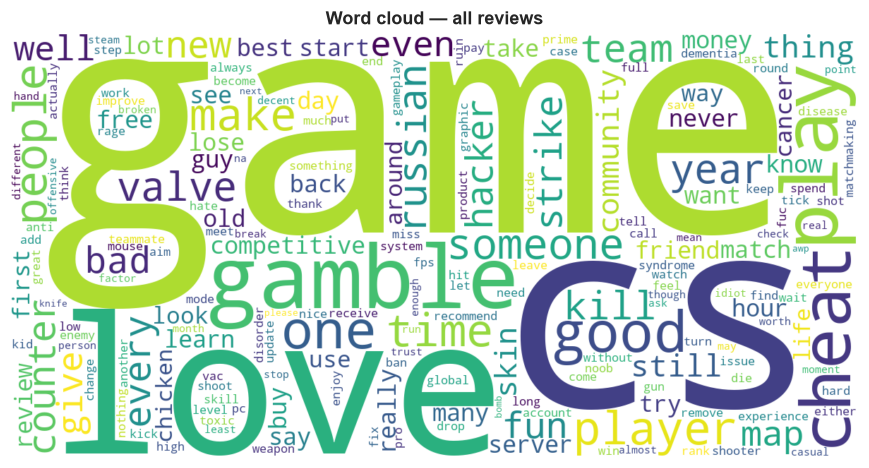

In [6]:
# Reload the processed reviews saved above
data = pd.read_csv(PROCESSED_PATH, parse_dates=["Date"])
show_wordcloud(join_text(data), "Word cloud — all reviews", "wordcloud_all")

### Before vs after 2023-09-29

Release of CS2, replacing CS:GO.

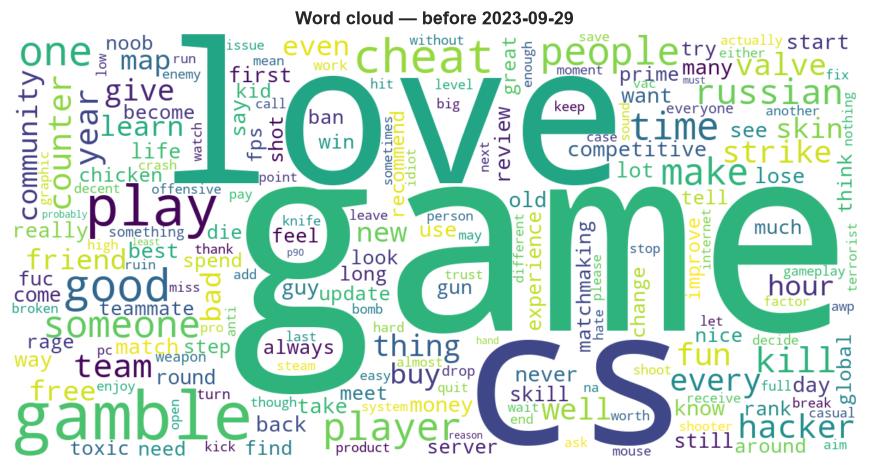

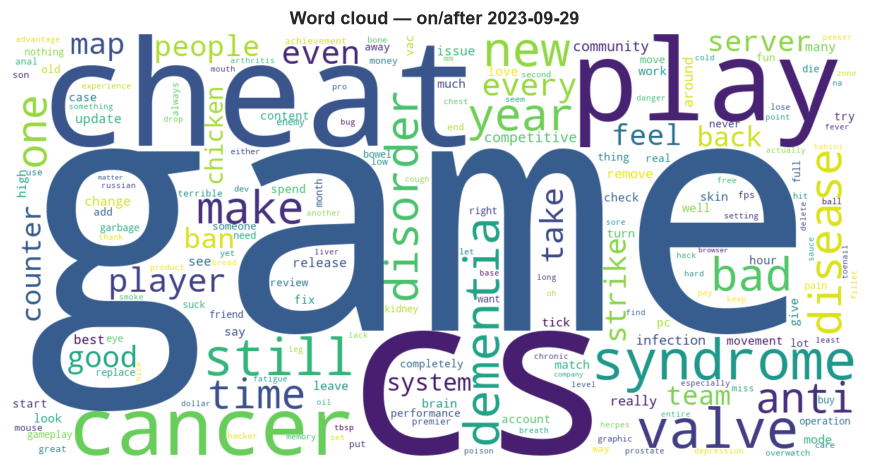

In [7]:
before_df, after_df = split_by_cutoff(data)

show_wordcloud(join_text(before_df), f"Word cloud — before {CUTOFF_DATE}", "wordcloud_before")
show_wordcloud(join_text(after_df), f"Word cloud — on/after {CUTOFF_DATE}", "wordcloud_after")

## Word frequencies

### All reviews

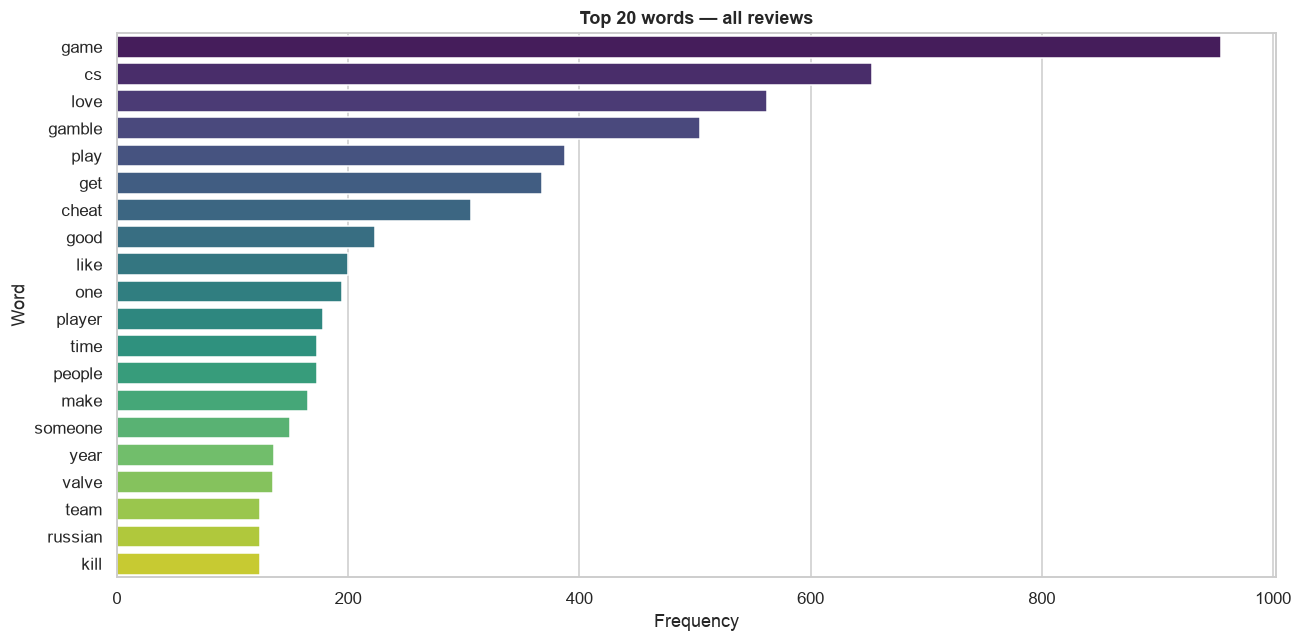

In [8]:
freq_df = top_words(data[TEXT_COLUMN])
save_table(freq_df, "top_words_all", index=False)
plot_top_words(freq_df, "Top 20 words — all reviews", "top_words_all")

### Before vs after 2023-09-29

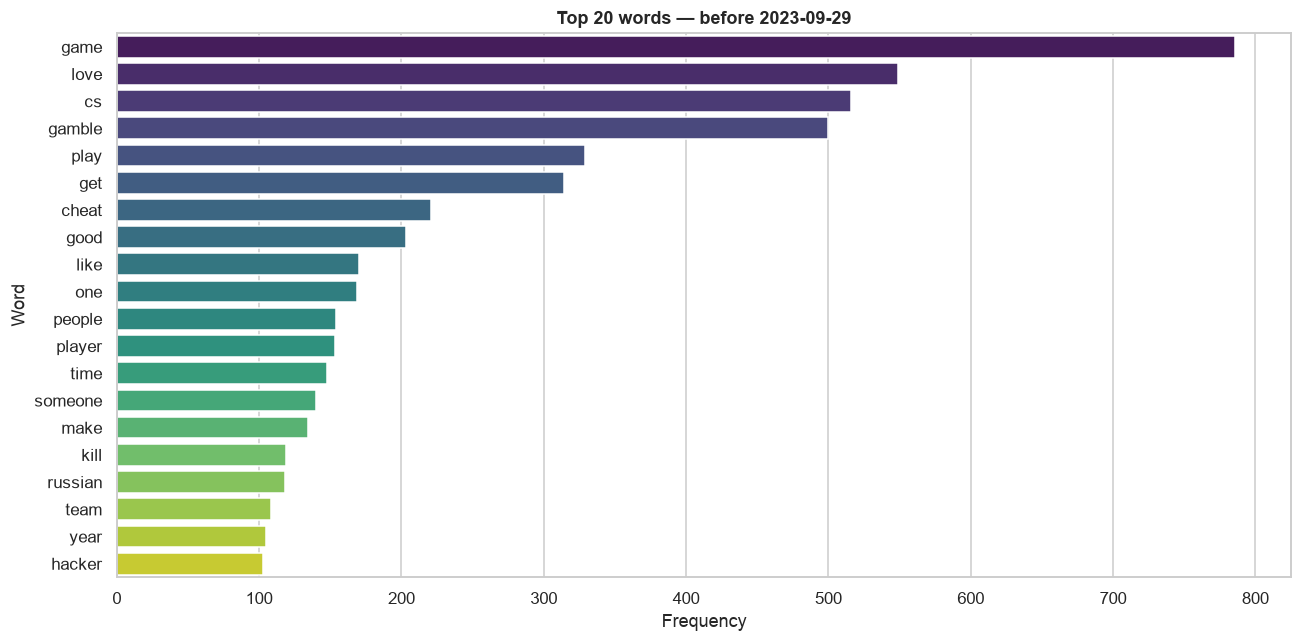

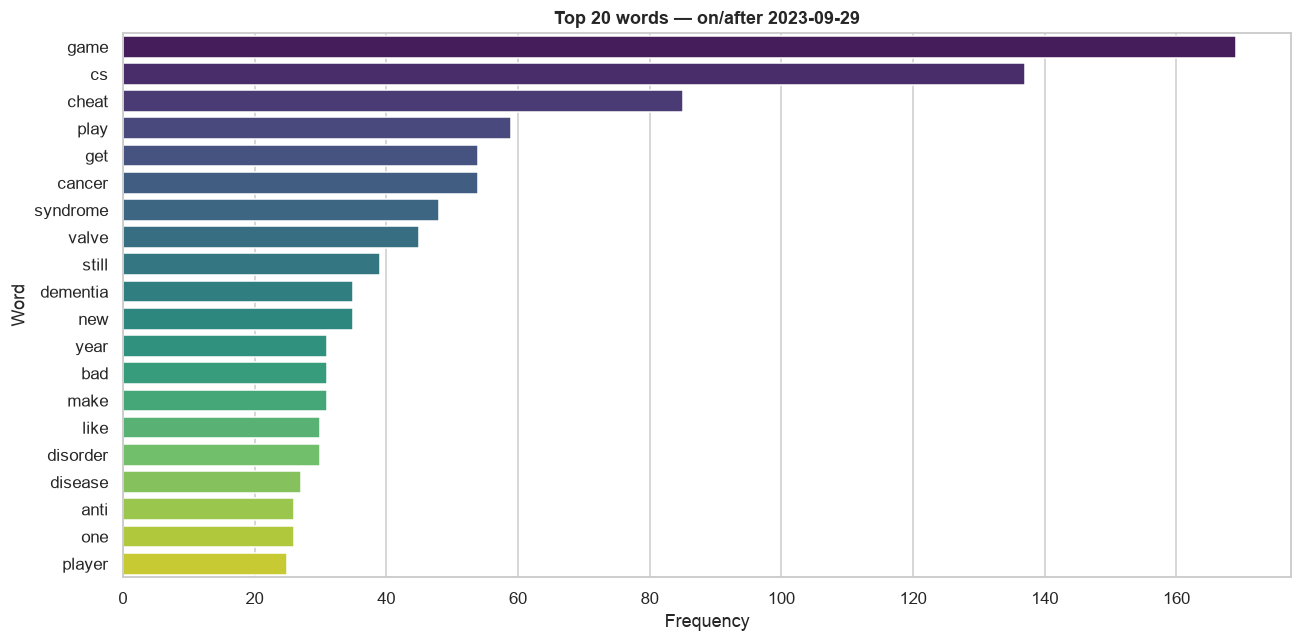

before            on/after          
       word frequency      word frequency
0      game       786      game       169
1      love       549        cs       137
2        cs       516     cheat        85
3    gamble       500      play        59
4      play       329       get        54
5       get       314    cancer        54
6     cheat       221  syndrome        48
7      good       203     valve        45
8      like       170     still        39
9       one       169  dementia        35
10   people       154       new        35
11   player       153      year        31
12     time       148       bad        31
13  someone       140      make        31
14     make       134      like        30
15     kill       119  disorder        30
16  russian       118   disease        27
17     team       108      anti        26
18     year       105       one        26
19   hacker       103    player        25

In [9]:
before_df, after_df = split_by_cutoff(data)
freq_before = top_words(before_df[TEXT_COLUMN])
freq_after = top_words(after_df[TEXT_COLUMN])

save_table(freq_before, "top_words_before", index=False)
save_table(freq_after, "top_words_after", index=False)
plot_top_words(freq_before, f"Top 20 words — before {CUTOFF_DATE}", "top_words_before")
plot_top_words(freq_after, f"Top 20 words — on/after {CUTOFF_DATE}", "top_words_after")

# Side-by-side comparison
pd.concat({"before": freq_before, "on/after": freq_after}, axis=1)

## Sentiment analysis (VADER)

VADER assigns each review a compound score in `[-1, 1]`:

| Score | Category |
|---|---|
| ≥ 0.05 | Positive |
| ≤ -0.05 | Negative |
| otherwise | Neutral |

The scored reviews are saved to `data/processed/Counter_Strike/Counter_Strike_sentiment.csv`.

In [10]:
sia = SentimentIntensityAnalyzer()


def get_sentiment_category(score):
    """Map a VADER compound score to Positive / Neutral / Negative."""
    if score >= 0.05:
        return "Positive"
    if score <= -0.05:
        return "Negative"
    return "Neutral"


data = data.dropna(subset=[TEXT_COLUMN]).copy()
data["sentiment_score"] = (
    data[TEXT_COLUMN].astype(str).apply(lambda text: sia.polarity_scores(text)["compound"])
)
data["sentiment_category"] = data["sentiment_score"].apply(get_sentiment_category)
save_table(data, "sentiment", index=False)

before_df, after_df = split_by_cutoff(data)
summary = pd.DataFrame(
    {
        "reviews": [len(before_df), len(after_df)],
        "mean_score": [before_df["sentiment_score"].mean(), after_df["sentiment_score"].mean()],
        "positive_share": [
            (before_df["sentiment_category"] == "Positive").mean(),
            (after_df["sentiment_category"] == "Positive").mean(),
        ],
    },
    index=[f"before {CUTOFF_DATE}", f"on/after {CUTOFF_DATE}"],
).round(3)
save_table(summary, "sentiment_summary")
summary

,reviews,mean_score,positive_share
before 2023-09-29,616,0.135,0.524
on/after 2023-09-29,124,-0.037,0.435


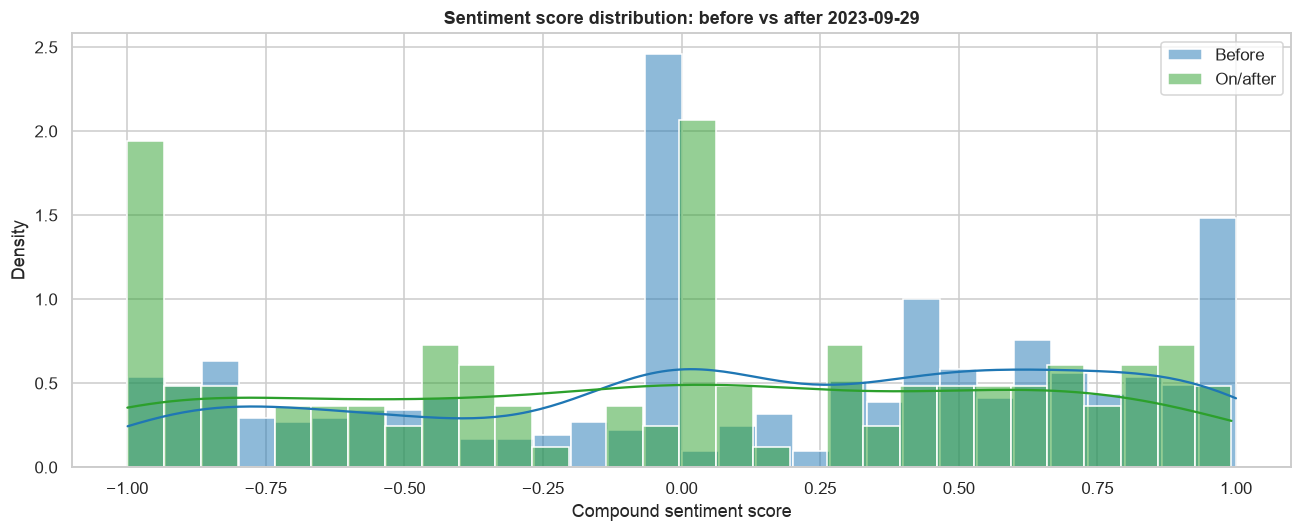

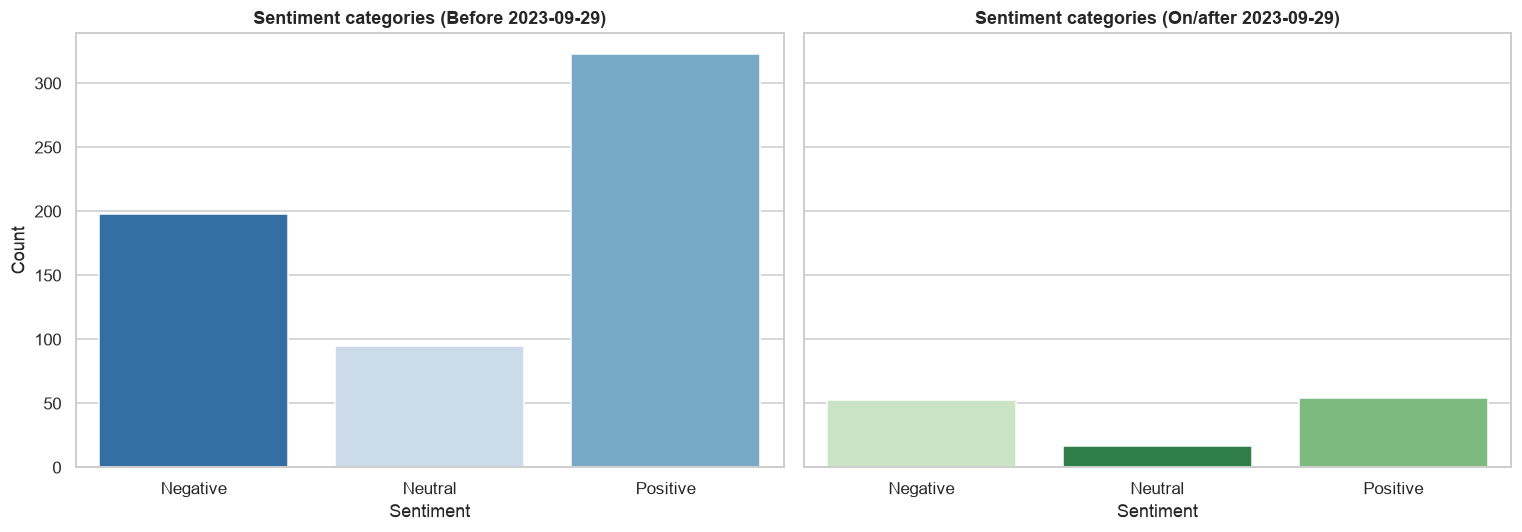

In [11]:
# Sentiment score distribution
plt.figure(figsize=(12, 5))
sns.histplot(
    before_df["sentiment_score"],
    color="tab:blue",
    kde=True,
    label="Before",
    bins=30,
    stat="density",
)
sns.histplot(
    after_df["sentiment_score"],
    color="tab:green",
    kde=True,
    label="On/after",
    bins=30,
    stat="density",
)
plt.title(f"Sentiment score distribution: before vs after {CUTOFF_DATE}")
plt.xlabel("Compound sentiment score")
plt.legend()
plt.tight_layout()
save_and_show("sentiment_distribution")

# Sentiment category counts
CATEGORY_ORDER = ["Negative", "Neutral", "Positive"]
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, subset, label, palette in [
    (axs[0], before_df, "Before", "Blues"),
    (axs[1], after_df, "On/after", "Greens"),
]:
    sns.countplot(
        data=subset,
        x="sentiment_category",
        hue="sentiment_category",
        order=CATEGORY_ORDER,
        palette=palette,
        legend=False,
        ax=ax,
    )
    ax.set_title(f"Sentiment categories ({label} {CUTOFF_DATE})")
    ax.set_xlabel("Sentiment")
axs[0].set_ylabel("Count")
plt.tight_layout()
save_and_show("sentiment_categories")

### Distribution fits

Normal, Laplace and rescaled Beta distributions are fitted to the sentiment scores to
see which shape best describes each period.

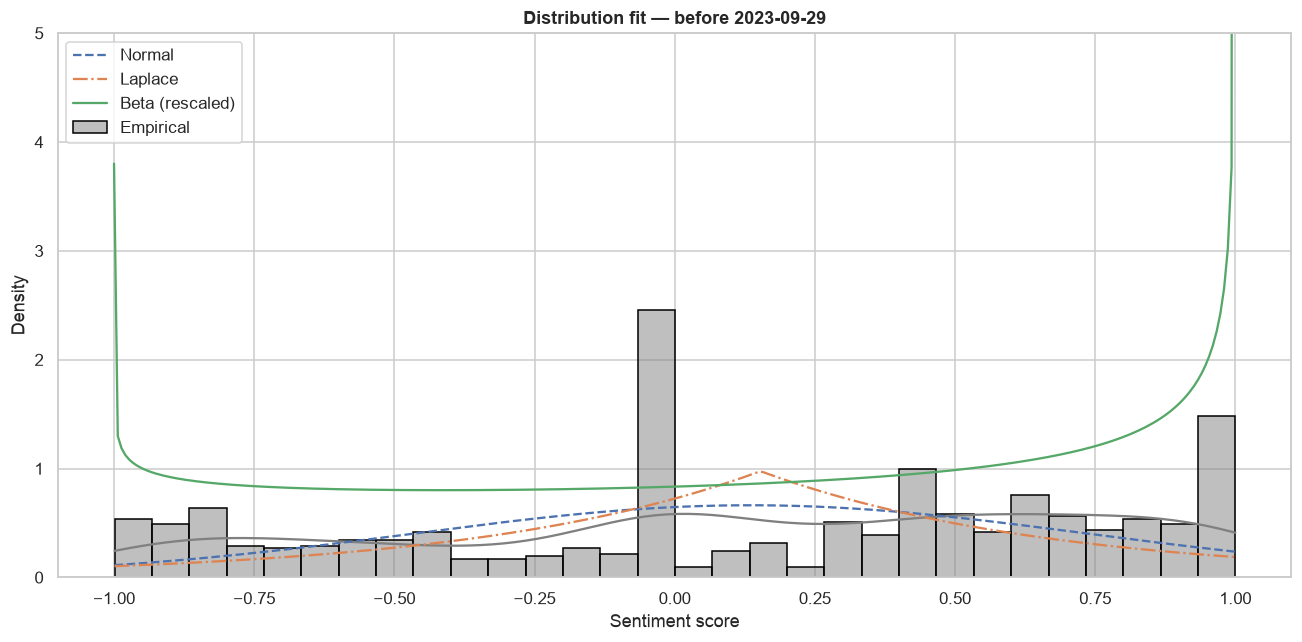

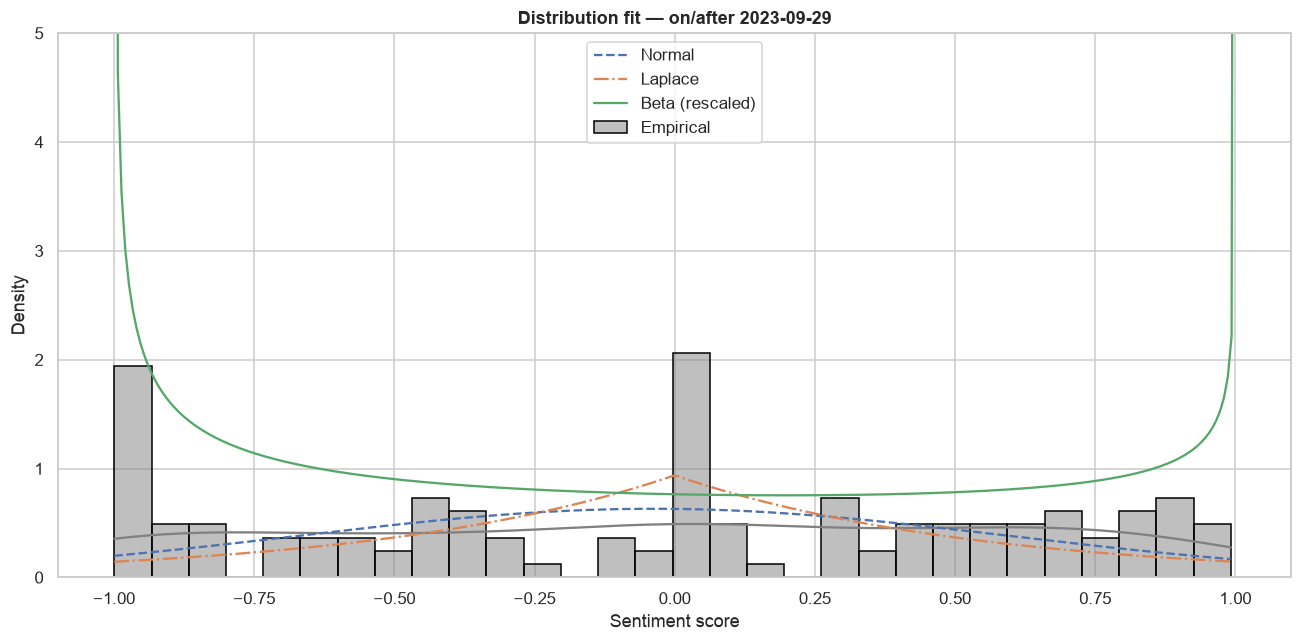

In [12]:
def compare_distributions(sample, title, filename):
    """Overlay Normal, Laplace and rescaled Beta fits on the empirical distribution."""
    plt.figure(figsize=(12, 6))
    sns.histplot(
        sample,
        kde=True,
        stat="density",
        bins=30,
        label="Empirical",
        color="gray",
        edgecolor="black",
    )
    x = np.linspace(sample.min(), sample.max(), 300)

    # Normal
    plt.plot(x, stats.norm.pdf(x, sample.mean(), sample.std()), label="Normal", linestyle="--")

    # Laplace
    loc, scale = stats.laplace.fit(sample)
    plt.plot(x, stats.laplace.pdf(x, loc, scale), label="Laplace", linestyle="-.")

    # Beta, rescaled from [-1, 1] to (0, 1) and back
    sample_beta = np.clip((sample + 1) / 2, 1e-6, 1 - 1e-6)
    a_beta, b_beta, _, _ = stats.beta.fit(sample_beta, floc=0, fscale=1)
    x_beta = np.linspace(1e-6, 1 - 1e-6, 300)
    plt.plot(x_beta * 2 - 1, stats.beta.pdf(x_beta, a_beta, b_beta), label="Beta (rescaled)")

    plt.title(f"Distribution fit — {title}")
    plt.xlabel("Sentiment score")
    plt.ylabel("Density")
    plt.ylim(0, 5)  # keep the tall peak at 0 from hiding the fits
    plt.legend()
    plt.tight_layout()
    save_and_show(filename)


compare_distributions(
    before_df["sentiment_score"], f"before {CUTOFF_DATE}", "distribution_fit_before"
)
compare_distributions(
    after_df["sentiment_score"], f"on/after {CUTOFF_DATE}", "distribution_fit_after"
)

### Average sentiment per year

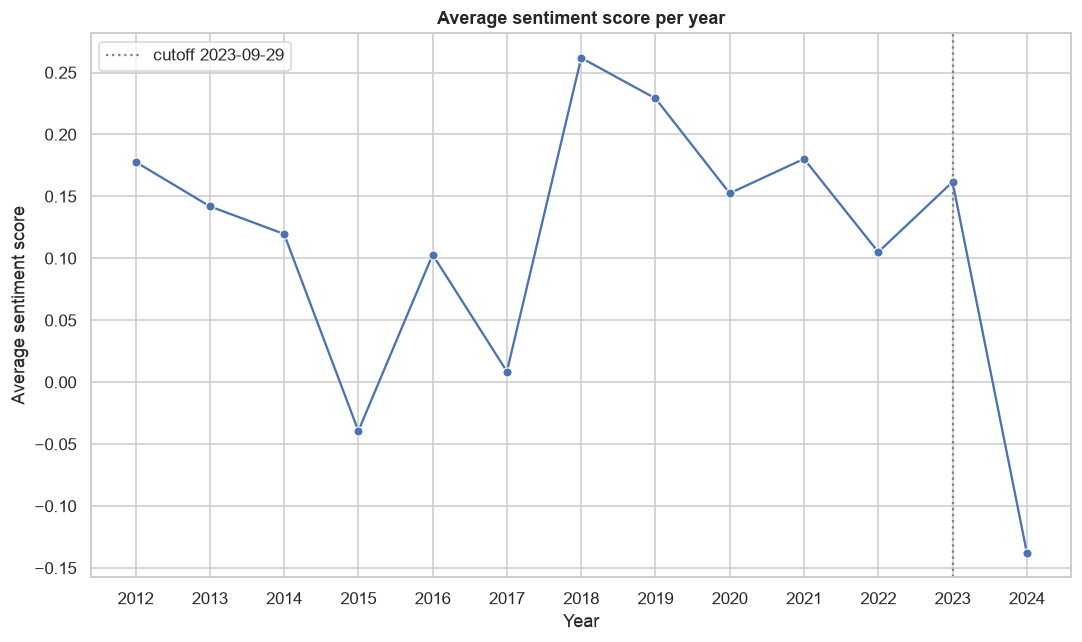

,Year,mean,count
0,2012,0.177900,1
1,2013,0.141975,12
2,2014,0.119626,57
3,2015,-0.039372,43
4,2016,0.102967,52
5,2017,0.008586,49
6,2018,0.261848,62
7,2019,0.229093,57
8,2020,0.152512,73
9,2021,0.180307,76


In [13]:
yearly_sentiment = data.groupby("Year")["sentiment_score"].agg(["mean", "count"]).reset_index()
yearly_sentiment["Year"] = yearly_sentiment["Year"].astype(int)
save_table(yearly_sentiment, "yearly_sentiment", index=False)

plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_sentiment, x="Year", y="mean", marker="o")
plt.axvline(
    pd.Timestamp(CUTOFF_DATE).year, color="gray", linestyle=":", label=f"cutoff {CUTOFF_DATE}"
)
plt.title("Average sentiment score per year")
plt.xlabel("Year")
plt.ylabel("Average sentiment score")
plt.xticks(yearly_sentiment["Year"])
plt.legend()
plt.tight_layout()
save_and_show("yearly_sentiment")

yearly_sentiment

### Word clouds per year

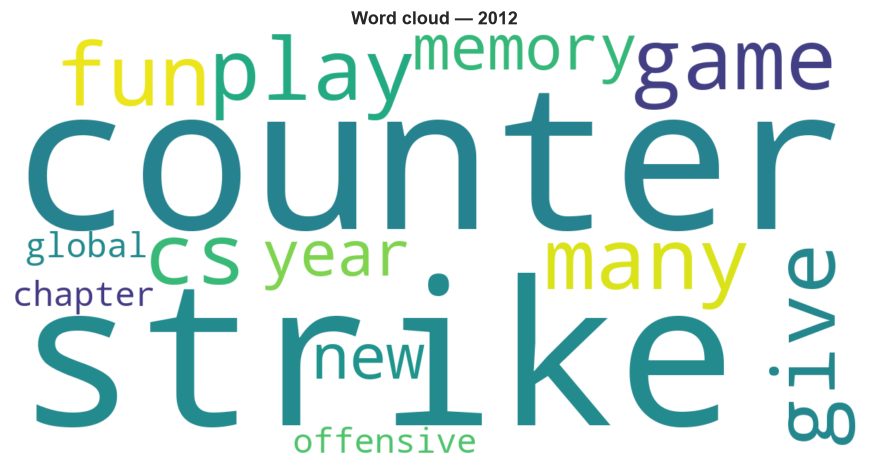

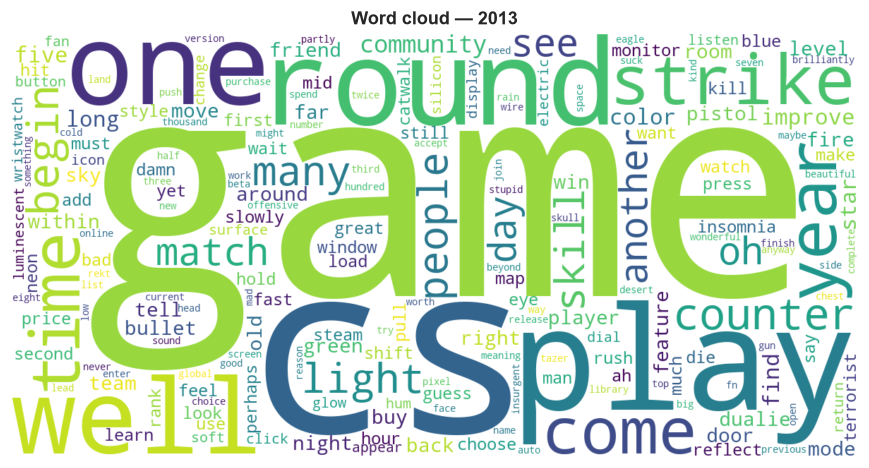

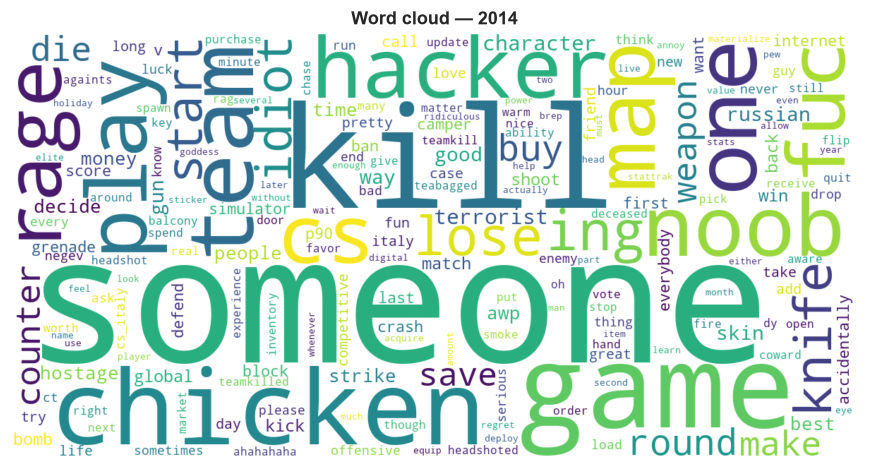

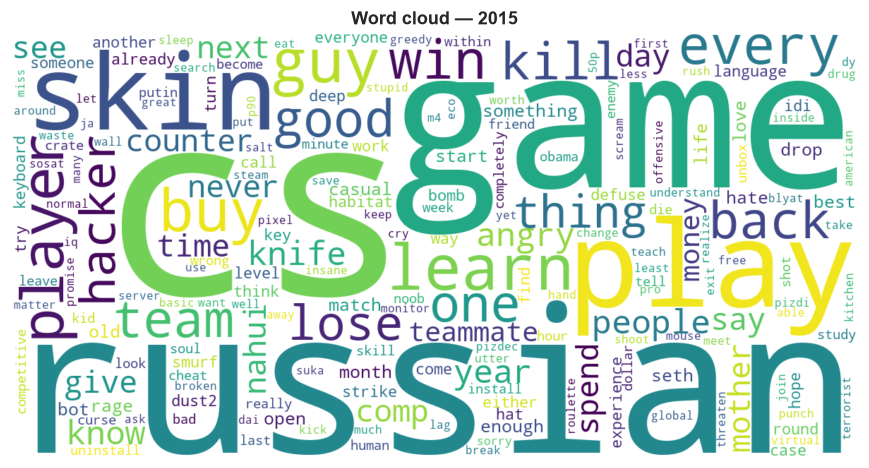

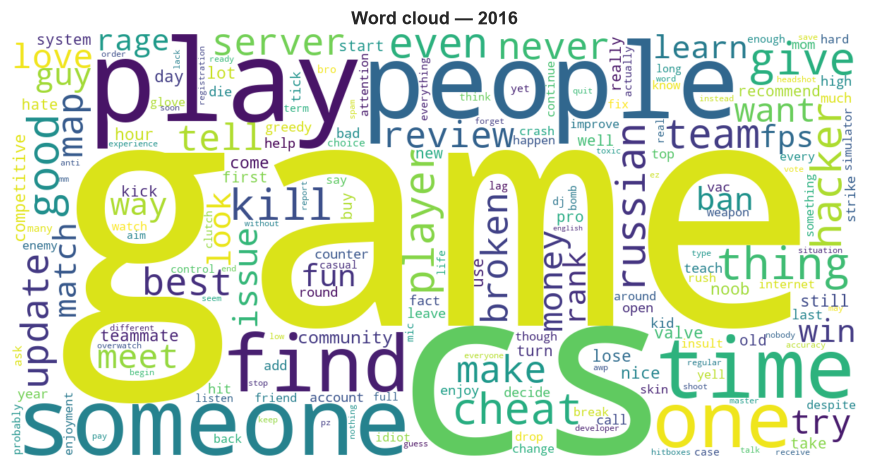

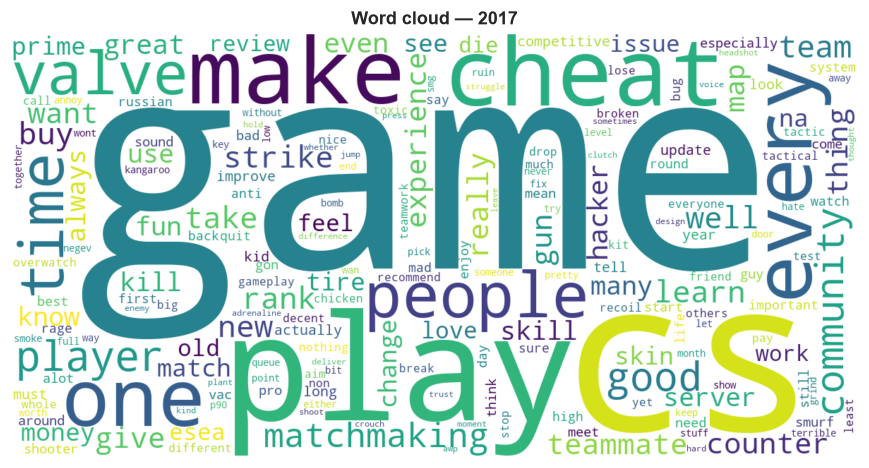

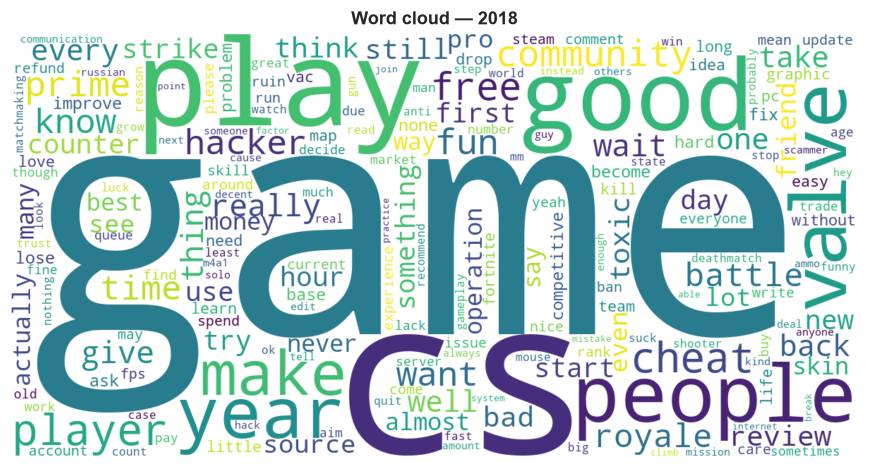

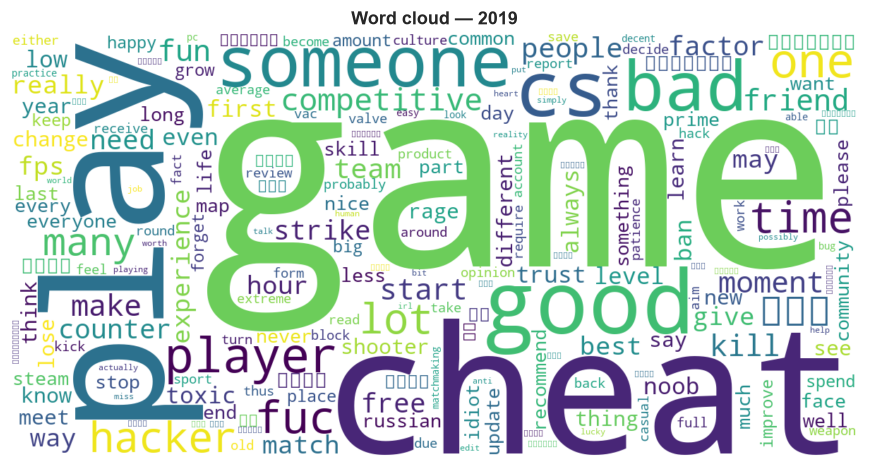

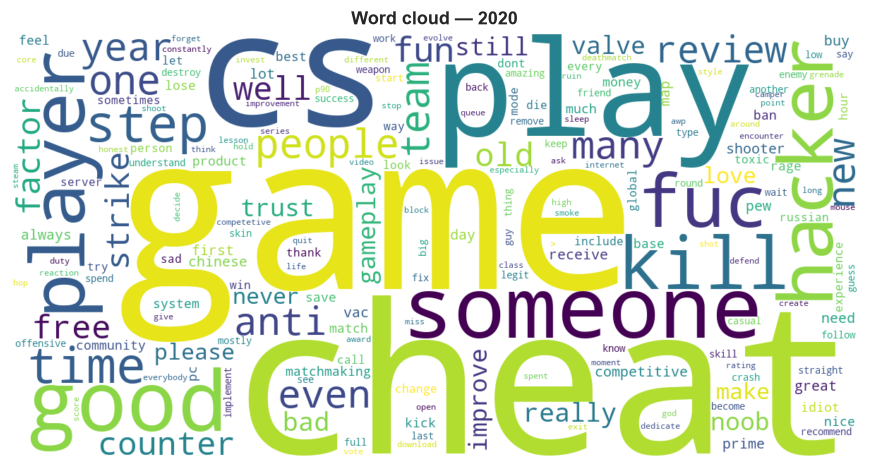

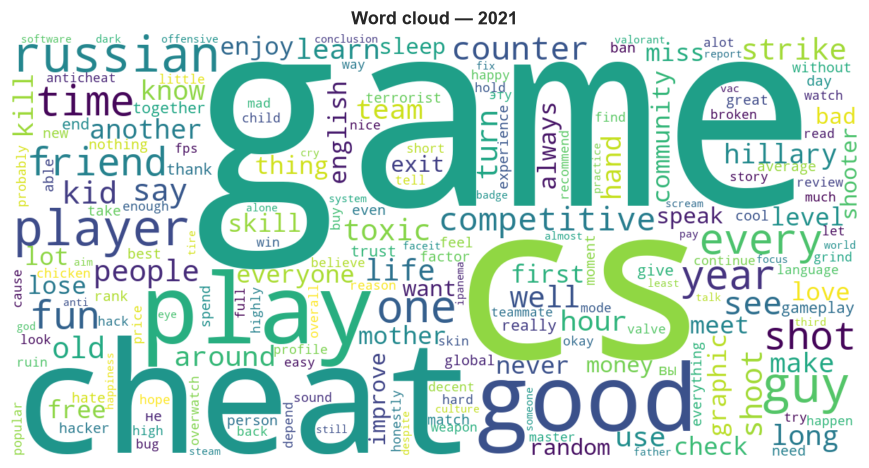

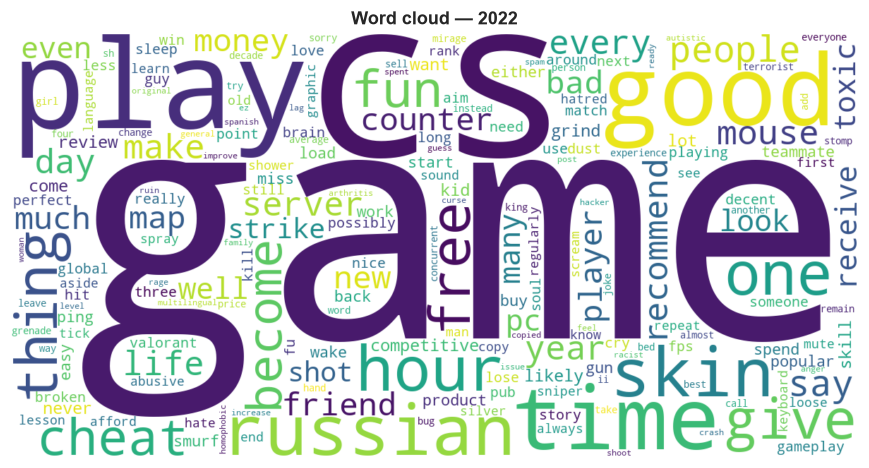

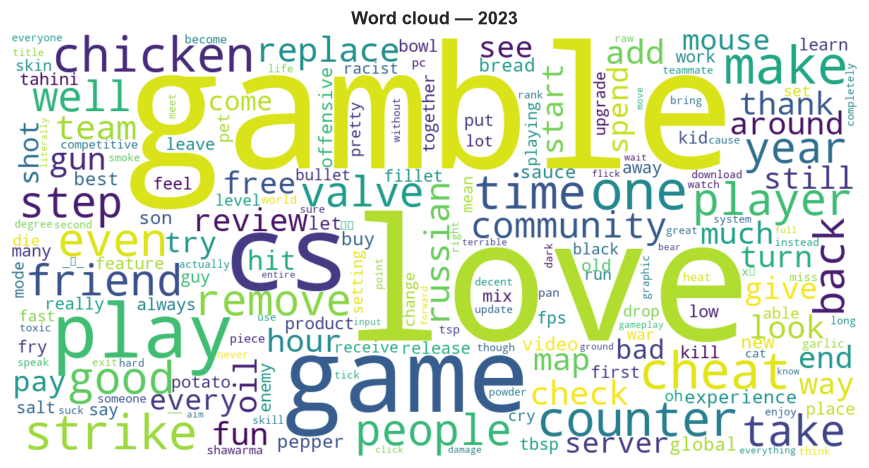

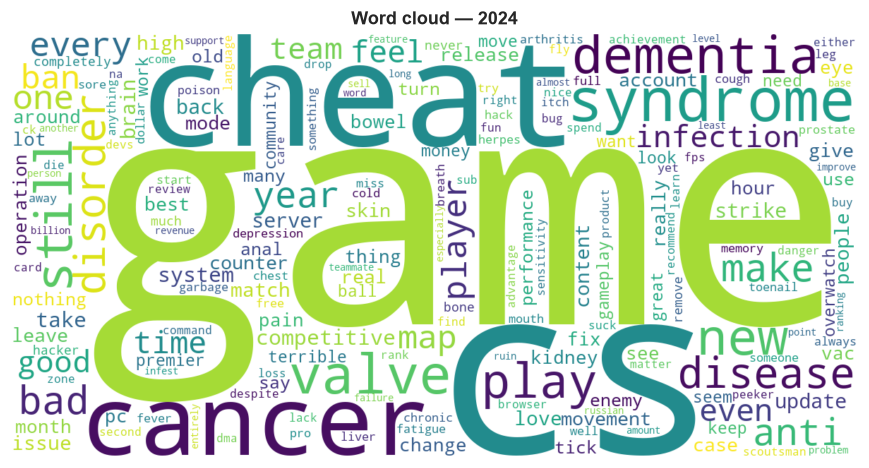

In [14]:
for year in sorted(data["Year"].dropna().astype(int).unique()):
    show_wordcloud(
        join_text(data[data["Year"] == year]), f"Word cloud — {year}", f"wordcloud_{year}"
    )

## Sentiment vs user recommendation

Does the text sentiment agree with whether the user recommended the game?

`Recommendation` is binary while the sentiment category has three levels, so a count
plot alone can be misleading. A box plot of the sentiment score per recommendation shows
the distributions directly, and may reveal whether *Neutral* reviews lean towards
*Recommended* — which would allow treating sentiment as a binary variable.

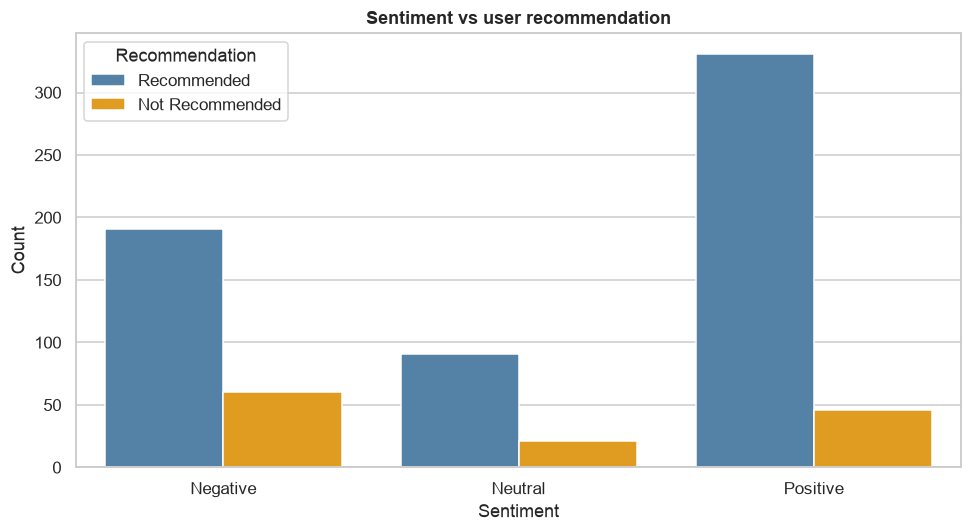

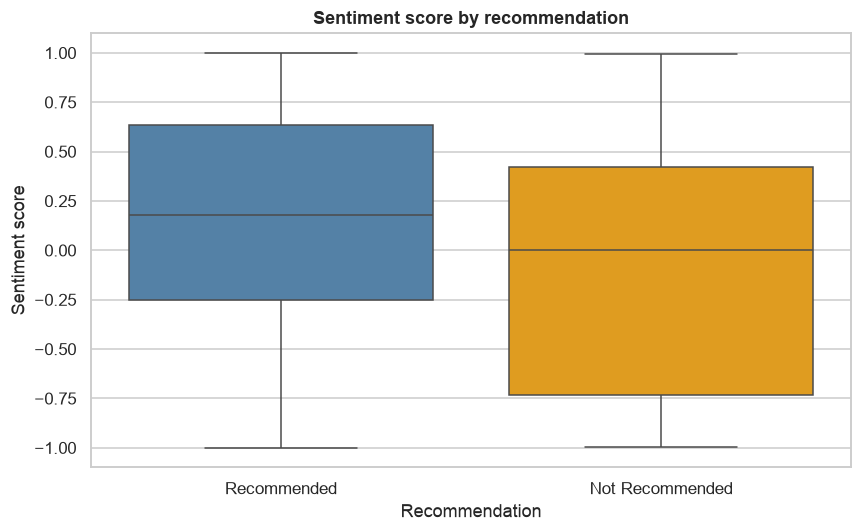

Missing 'Recommendation' values: 0


Recommendation,Not Recommended,Recommended,All
sentiment_category,,,
Negative,60,191,251
Neutral,21,91,112
Positive,46,331,377
All,127,613,740


In [15]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=data,
    x="sentiment_category",
    hue="Recommendation",
    order=CATEGORY_ORDER,
    hue_order=RECOMMENDATION_ORDER,
    palette=RECOMMENDATION_PALETTE,
)
plt.title("Sentiment vs user recommendation")
plt.ylabel("Count")
plt.xlabel("Sentiment")
plt.tight_layout()
save_and_show("sentiment_vs_recommendation")

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=data,
    x="Recommendation",
    y="sentiment_score",
    hue="Recommendation",
    order=RECOMMENDATION_ORDER,
    palette=RECOMMENDATION_PALETTE,
    legend=False,
)
plt.title("Sentiment score by recommendation")
plt.ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_by_recommendation")

print(f"Missing 'Recommendation' values: {data['Recommendation'].isna().sum()}")
crosstab = pd.crosstab(data["sentiment_category"], data["Recommendation"], margins=True)
save_table(crosstab, "sentiment_vs_recommendation")
crosstab

**Observations**

- *Recommended*: the median sentiment score is positive but close to neutral; more than 50% of the data falls into the negative category.
- *Not Recommended*: the median sentiment score is close to 0 and 50% of the reviews have a negative sentiment score.

## Sentiment, recommendation, hours played and helpful votes

Metadata such as **Hours Played** and **Helpful Votes** adds context to the review text.

**Variables**

- **Sentiment score** – text sentiment
- **Recommendation** – positive / negative game recommendation
- **Hours played** – time spent in the game, an indicator of engagement
- **Helpful votes** – number of users who found the review helpful

**Why metadata?**

- Many hours combined with negative sentiment may indicate valid, constructive criticism.
- Helpful votes reflect the perceived quality of a review; many votes suggest a more
  influential opinion.

**Research questions**

1. Do highly engaged users (many hours played) express more polarized sentiment?
2. Are reviews with few helpful votes more neutral or noisy?
3. Do *Not Recommended* reviews with many helpful votes form separate clusters?

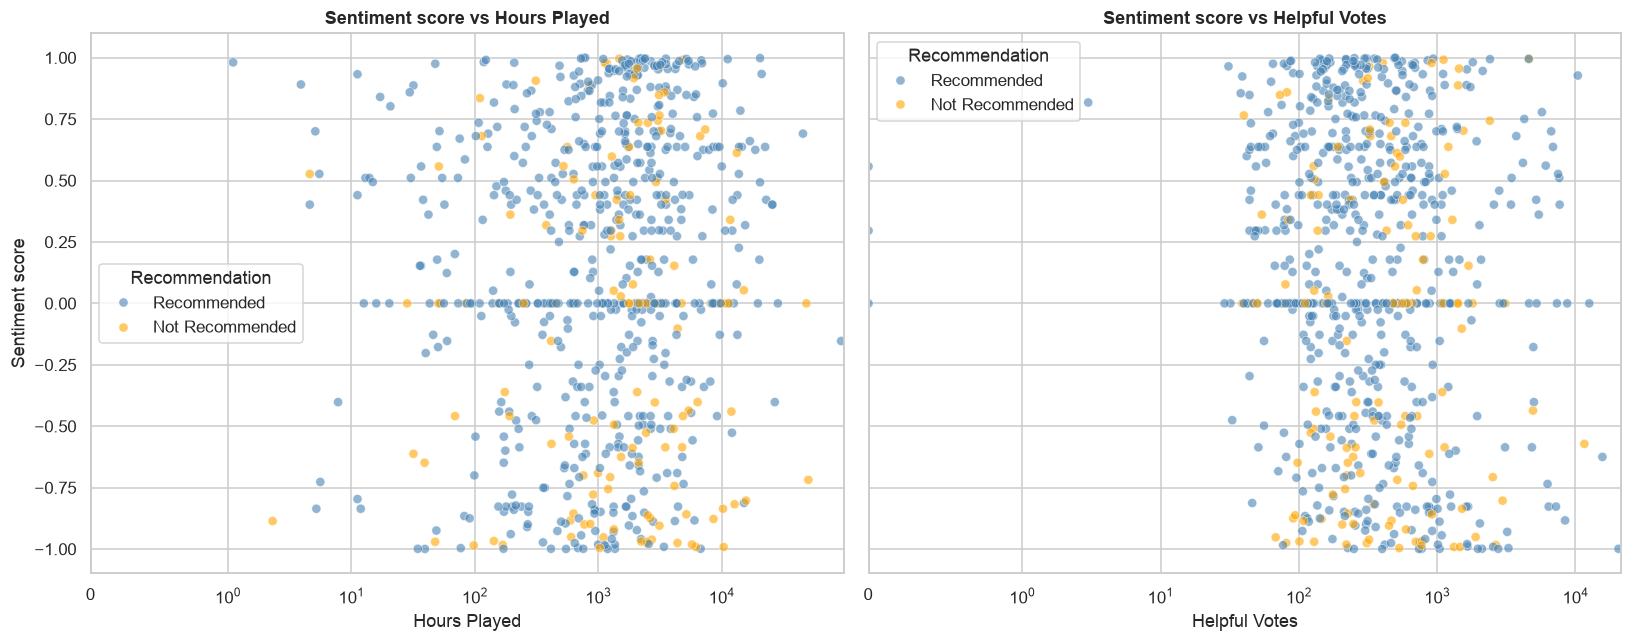

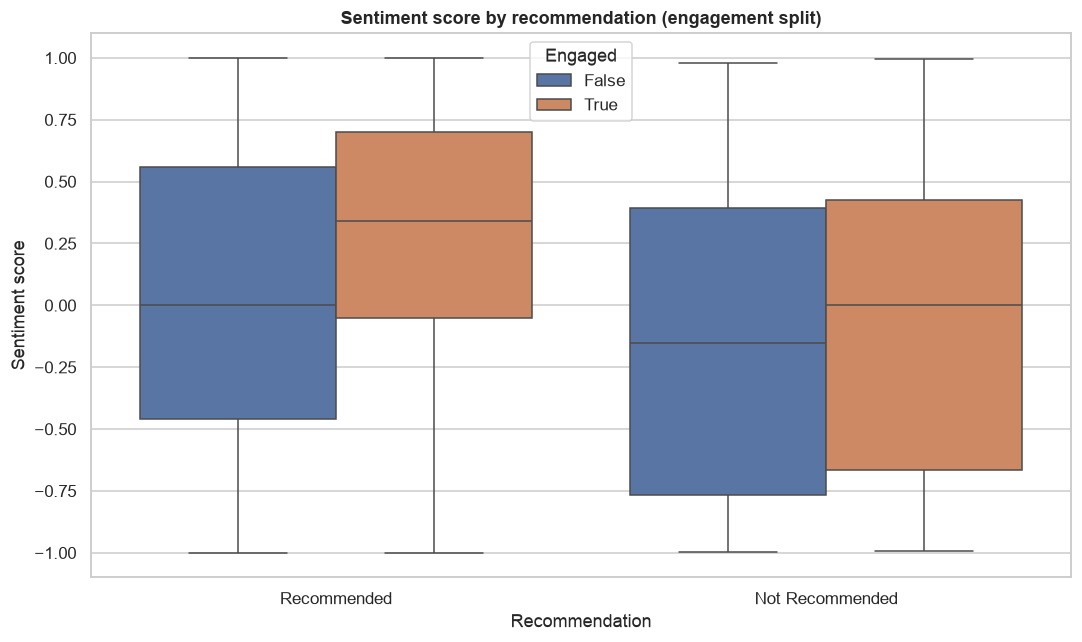

In [16]:
NUMERIC_COLUMNS = ["Hours Played", "Helpful Votes", "sentiment_score"]
METRICS = ["Hours Played", "Helpful Votes"]
PERIODS = ["Before", "After"]

df = data.copy()
df[NUMERIC_COLUMNS] = df[NUMERIC_COLUMNS].apply(pd.to_numeric, errors="coerce")
df["Period"] = np.where(df["Date"] < pd.Timestamp(CUTOFF_DATE), "Before", "After")

df_clean = df.dropna(subset=[*NUMERIC_COLUMNS, "Recommendation"]).copy()
df_clean["Engaged"] = df_clean["Hours Played"] > df_clean["Hours Played"].median()

# Sentiment vs hours played / helpful votes (log scale handles skew and outliers)
fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, metric in zip(axs, METRICS):
    sns.scatterplot(
        data=df_clean,
        x=metric,
        y="sentiment_score",
        hue="Recommendation",
        hue_order=RECOMMENDATION_ORDER,
        palette=RECOMMENDATION_PALETTE,
        alpha=0.6,
        ax=ax,
    )
    ax.set_xscale("symlog", linthresh=1)  # log scale that keeps 0 values
    ax.set_xlim(left=0)
    ax.set_title(f"Sentiment score vs {metric}")
    ax.set_ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_vs_metadata")

# Sentiment by recommendation, split by engagement (above-median hours played)
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_clean,
    x="Recommendation",
    y="sentiment_score",
    hue="Engaged",
    order=RECOMMENDATION_ORDER,
)
plt.title("Sentiment score by recommendation (engagement split)")
plt.ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_by_engagement")

### Before vs after 2023-09-29

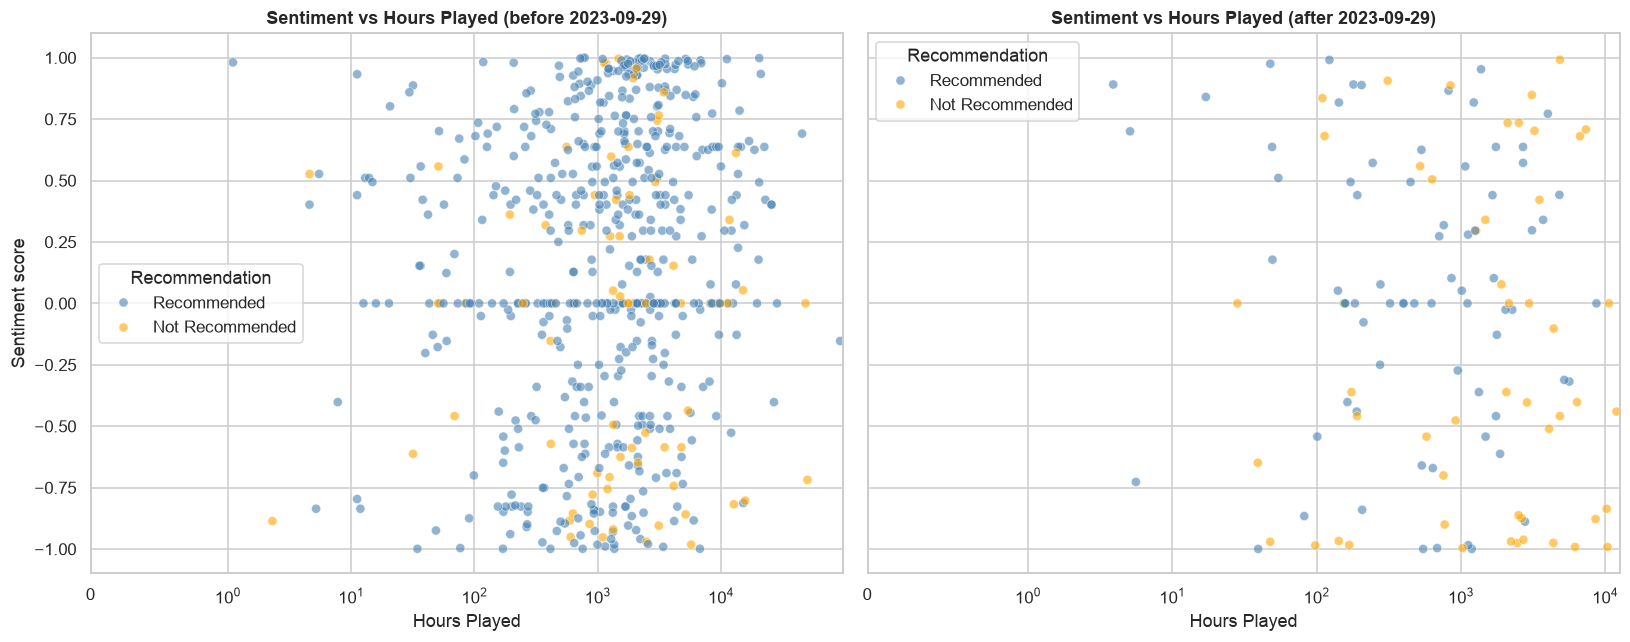

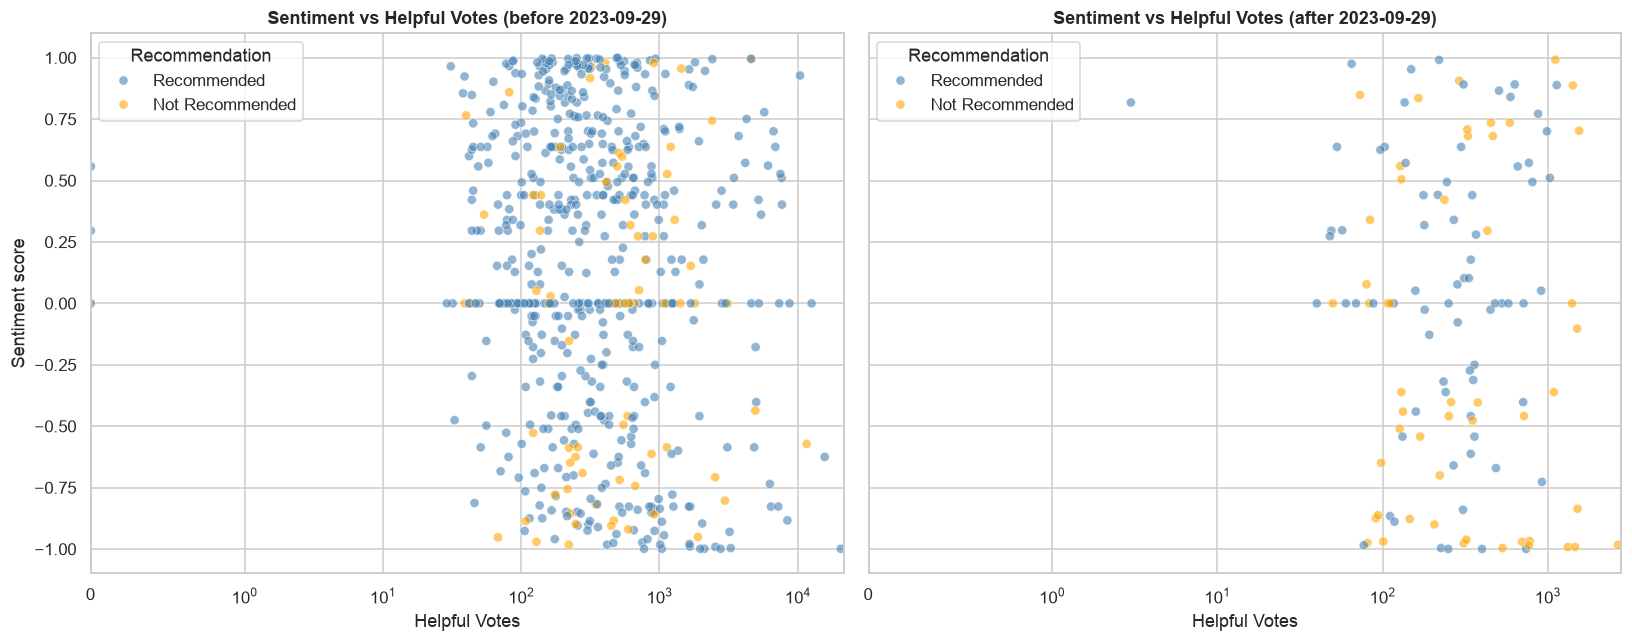

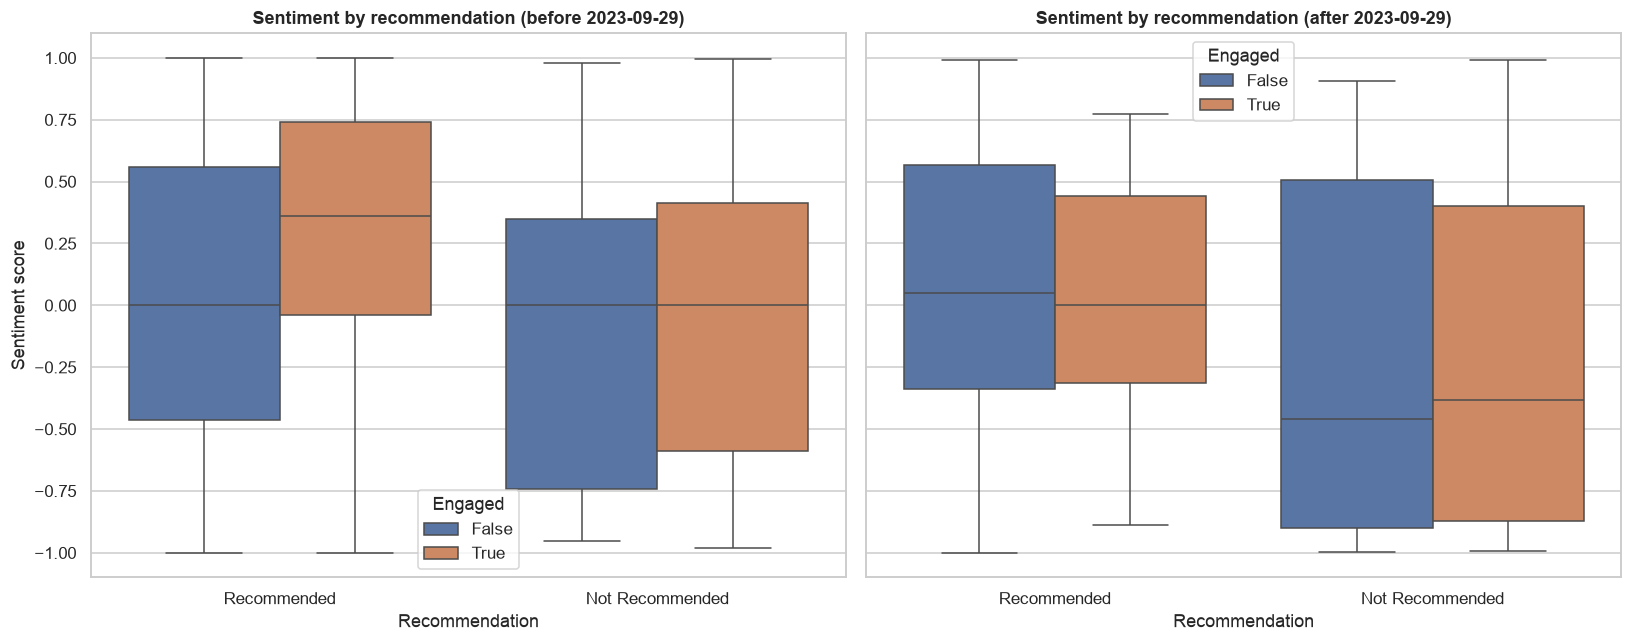

In [17]:
# Sentiment vs hours played / helpful votes, per period
for metric in METRICS:
    fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
    for ax, period in zip(axs, PERIODS):
        sns.scatterplot(
            data=df_clean[df_clean["Period"] == period],
            x=metric,
            y="sentiment_score",
            hue="Recommendation",
            hue_order=RECOMMENDATION_ORDER,
            palette=RECOMMENDATION_PALETTE,
            alpha=0.6,
            ax=ax,
        )
        ax.set_xscale("symlog", linthresh=1)  # log scale that keeps 0 values
        ax.set_xlim(left=0)
        ax.set_title(f"Sentiment vs {metric} ({period.lower()} {CUTOFF_DATE})")
        ax.set_ylabel("Sentiment score")
    plt.tight_layout()
    save_and_show(f"sentiment_vs_{metric.lower().replace(' ', '_')}_by_period")

# Sentiment by recommendation and engagement, per period
fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, period in zip(axs, PERIODS):
    sns.boxplot(
        data=df_clean[df_clean["Period"] == period],
        x="Recommendation",
        y="sentiment_score",
        hue="Engaged",
        order=RECOMMENDATION_ORDER,
        ax=ax,
    )
    ax.set_title(f"Sentiment by recommendation ({period.lower()} {CUTOFF_DATE})")
    ax.set_ylabel("Sentiment score")
plt.tight_layout()
save_and_show("sentiment_by_engagement_by_period")

### Hours played by sentiment category

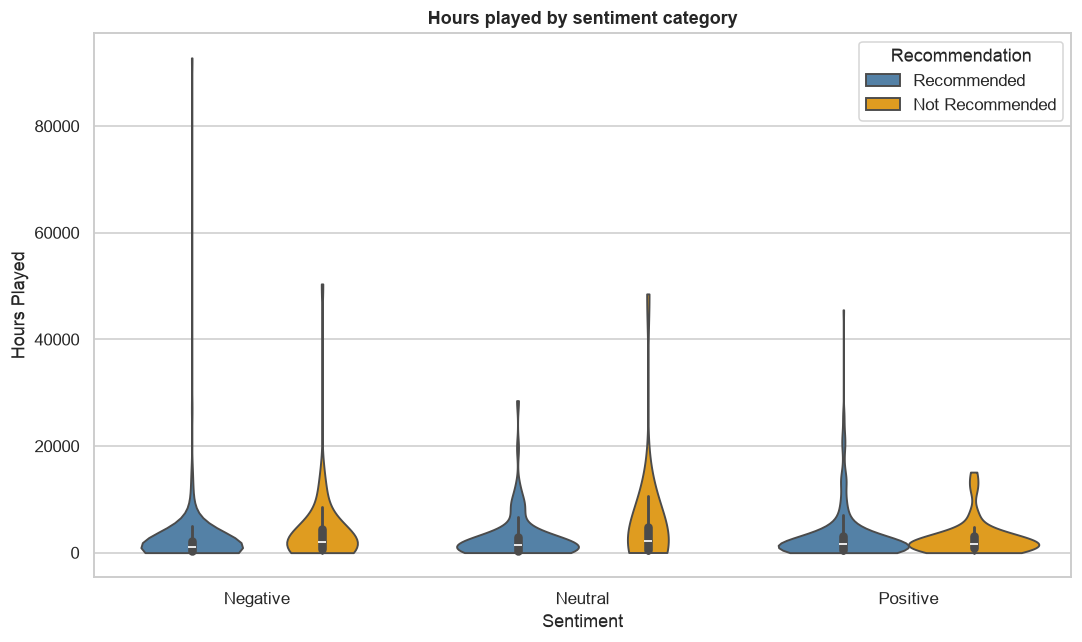

In [18]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df_clean,
    x="sentiment_category",
    y="Hours Played",
    hue="Recommendation",
    order=CATEGORY_ORDER,
    hue_order=RECOMMENDATION_ORDER,
    palette=RECOMMENDATION_PALETTE,
    cut=0,
)
plt.title("Hours played by sentiment category")
plt.xlabel("Sentiment")
plt.tight_layout()
save_and_show("hours_played_by_sentiment")

### Correlations

In [19]:
# Pearson correlation of sentiment with engagement metrics, per period
correlations = pd.DataFrame(
    {
        period: {
            f"sentiment vs {metric}": group["sentiment_score"].corr(group[metric])
            for metric in METRICS
        }
        for period, group in df_clean.groupby("Period")
    }
)[PERIODS].round(4)
save_table(correlations, "correlations")
correlations

,Before,After
sentiment vs Hours Played,0.0379,-0.1341
sentiment vs Helpful Votes,-0.1066,-0.0541


## Saved outputs

Everything this notebook produced:

In [20]:
tables = sorted(p.name for p in OUTPUT_DIR.glob("*.csv"))
figures = sorted(p.name for p in FIGURES_DIR.glob("*.png"))
print(f"Tables in {OUTPUT_DIR.relative_to(PROJECT_ROOT)}/:", *tables, sep="\n  ")
print(
    f"\n{len(figures)} figures in {FIGURES_DIR.relative_to(PROJECT_ROOT)}/:", *figures, sep="\n  "
)

Tables in data/processed/Counter_Strike/:
  Counter_Strike_cleaned_processed_reviews.csv
  Counter_Strike_correlations.csv
  Counter_Strike_documents.csv
  Counter_Strike_metadata.csv
  Counter_Strike_sentiment.csv
  Counter_Strike_sentiment_summary.csv
  Counter_Strike_sentiment_vs_recommendation.csv
  Counter_Strike_top_words_after.csv
  Counter_Strike_top_words_all.csv
  Counter_Strike_top_words_before.csv
  Counter_Strike_yearly_sentiment.csv

32 figures in data/processed/Counter_Strike/figures/:
  distribution_fit_after.png
  distribution_fit_before.png
  hours_played_by_sentiment.png
  sentiment_by_engagement.png
  sentiment_by_engagement_by_period.png
  sentiment_by_recommendation.png
  sentiment_categories.png
  sentiment_distribution.png
  sentiment_vs_helpful_votes_by_period.png
  sentiment_vs_hours_played_by_period.png
  sentiment_vs_metadata.png
  sentiment_vs_recommendation.png
  top_words_after.png
  top_words_all.png
  top_words_before.png
  wordcloud_2012.png
  wordclou